In [1]:
import os
import urllib.request
import zipfile

os.makedirs("data", exist_ok=True)

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

zip_path = "data/bank_marketing.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("data")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [2]:
import os

for root, dirs, files in os.walk("data"):
    for file in files:
        print(os.path.join(root, file))

data\bank-additional.zip
data\bank.zip
data\bank_marketing.zip


In [3]:
import zipfile
import os

with zipfile.ZipFile("data/bank-additional.zip", "r") as zip_ref:
    zip_ref.extractall("data/bank-additional")

for root, dirs, files in os.walk("data/bank-additional"):
    for file in files:
        print(os.path.join(root, file))

data/bank-additional\bank-additional\.DS_Store
data/bank-additional\bank-additional\.Rhistory
data/bank-additional\bank-additional\bank-additional-full.csv
data/bank-additional\bank-additional\bank-additional-names.txt
data/bank-additional\bank-additional\bank-additional.csv
data/bank-additional\__MACOSX\._bank-additional
data/bank-additional\__MACOSX\bank-additional\._.DS_Store


In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "data/bank-additional/bank-additional/bank-additional-full.csv",
    sep=';'
)

print("Dataset loaded successfully!")
print("\nShape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nDataset information:")
df.info()

Dataset loaded successfully!

Shape: (41188, 21)

First 5 rows:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   4118

In [5]:
print("Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nUnknown Values in Each Column:")
for col in df.select_dtypes(include='object').columns:
    count = (df[col] == 'unknown').sum()
    if count > 0:
        print(f"{col}: {count}")

print("\nTarget Variable Distribution:")
print(df['y'].value_counts())

print("\nTarget Variable Percentage:")
print(df['y'].value_counts(normalize=True) * 100)

Dataset Shape: (41188, 21)

Duplicate Rows: 12

Missing Values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Unknown Values in Each Column:
job: 330
marital: 80
education: 1731
default: 8597
housing: 990
loan: 990

Target Variable Distribution:
y
no     36548
yes     4640
Name: count, dtype: int64

Target Variable Percentage:
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


C:\Users\LaptopUser\AppData\Local\Temp\ipykernel_17296\3058321197.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [6]:
unknown_summary = pd.DataFrame({
    'Unknown Count': [
        (df[col] == 'unknown').sum()
        for col in df.select_dtypes(include=['str']).columns
    ]
})

unknown_summary['Percentage'] = (
    unknown_summary['Unknown Count'] / len(df) * 100
)

unknown_summary = unknown_summary[
    unknown_summary['Unknown Count'] > 0
].sort_values('Unknown Count', ascending=False)

display(unknown_summary)

,Unknown Count,Percentage
3,8597,20.872584
2,1731,4.202680
4,990,2.403613
5,990,2.403613
0,330,0.801204
1,80,0.194231


In [7]:
# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Display unknown-value summary with column names
unknown_summary = pd.DataFrame({
    'Feature': [
        col for col in df.select_dtypes(include=['str']).columns
        if (df[col] == 'unknown').sum() > 0
    ]
})

unknown_summary['Unknown Count'] = unknown_summary['Feature'].apply(
    lambda col: (df[col] == 'unknown').sum()
)

unknown_summary['Percentage'] = (
    unknown_summary['Unknown Count'] / len(df) * 100
)

print("Dataset after removing duplicates:", df.shape)
display(unknown_summary)

Dataset after removing duplicates: (41176, 21)


,Feature,Unknown Count,Percentage
0,job,330,0.801438
1,marital,80,0.194288
2,education,1730,4.201477
3,default,8596,20.876239
4,housing,990,2.404313
5,loan,990,2.404313


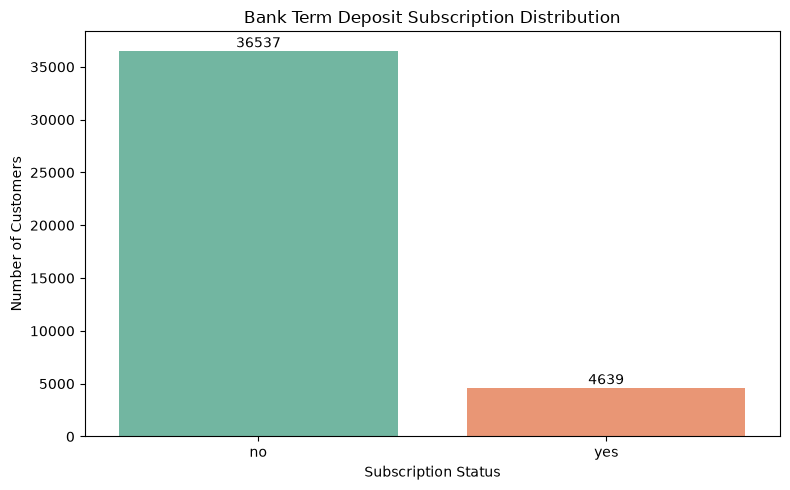

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='y',
    hue='y',
    palette='Set2',
    legend=False
)

plt.title('Bank Term Deposit Subscription Distribution')
plt.xlabel('Subscription Status')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig('target_distribution.png', dpi=300)
plt.show()

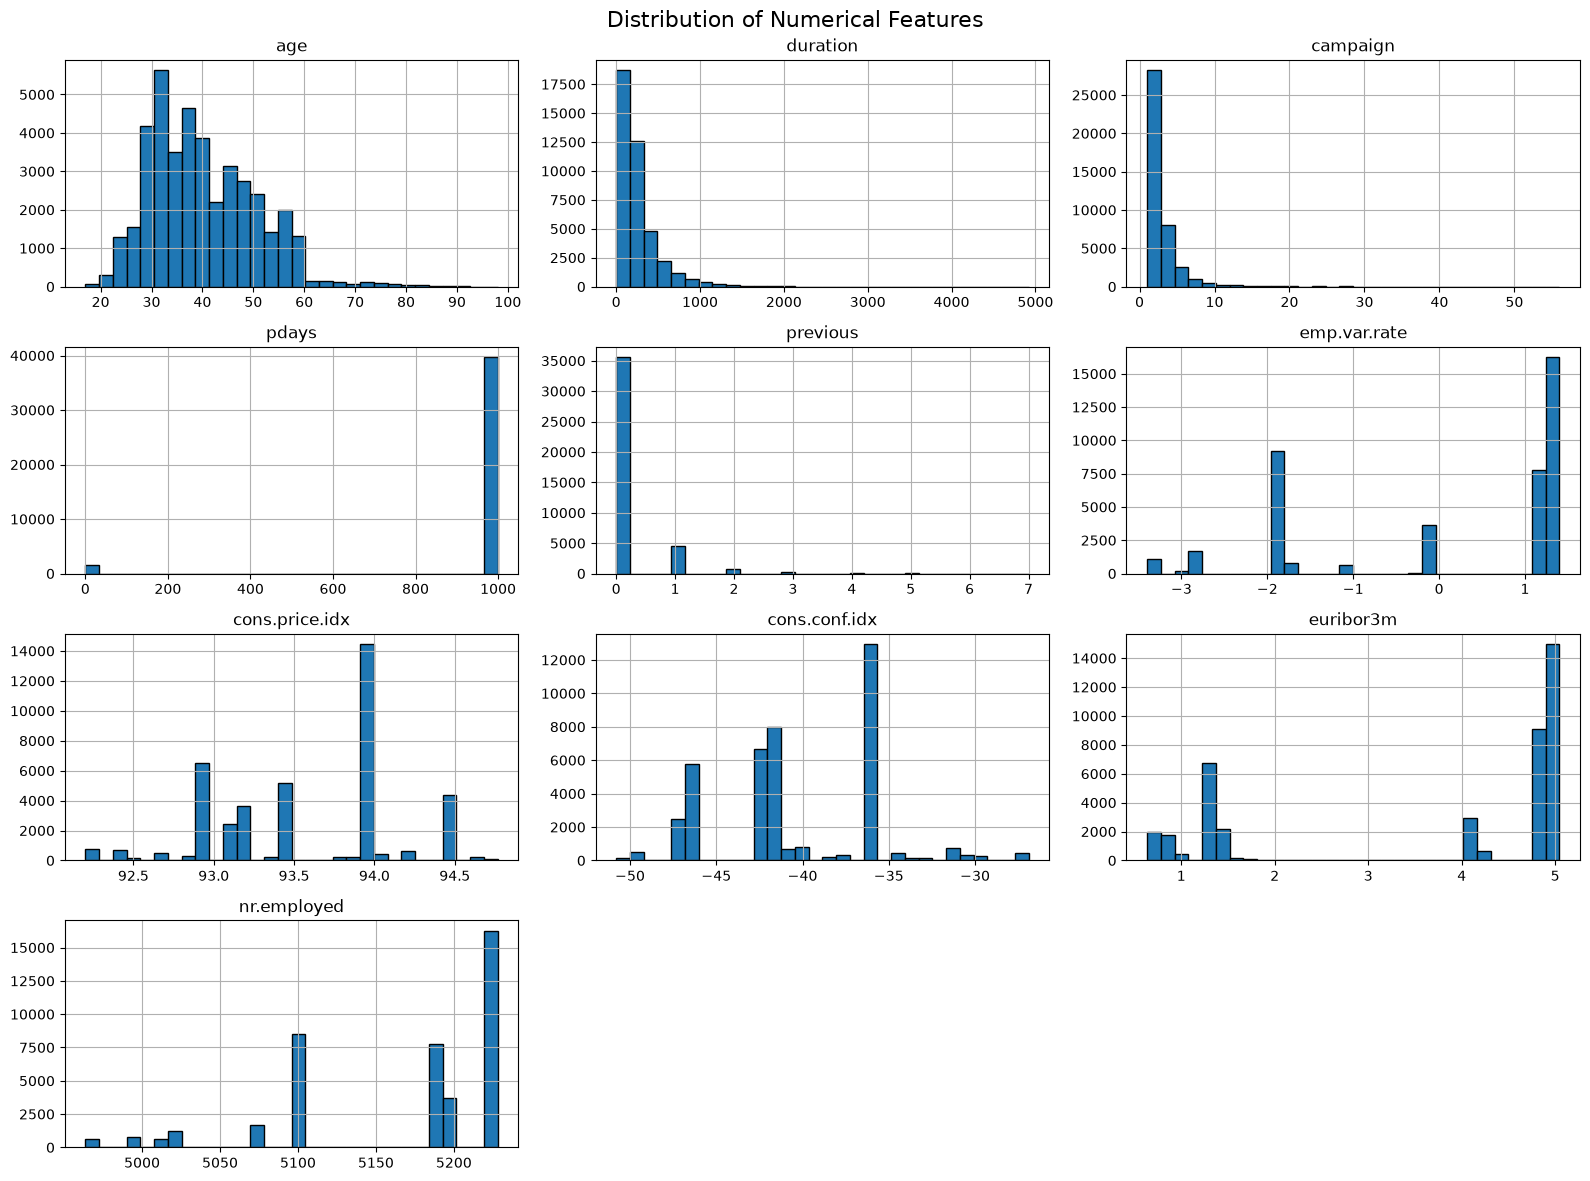

In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.savefig('numerical_feature_distributions.png', dpi=300)
plt.show()

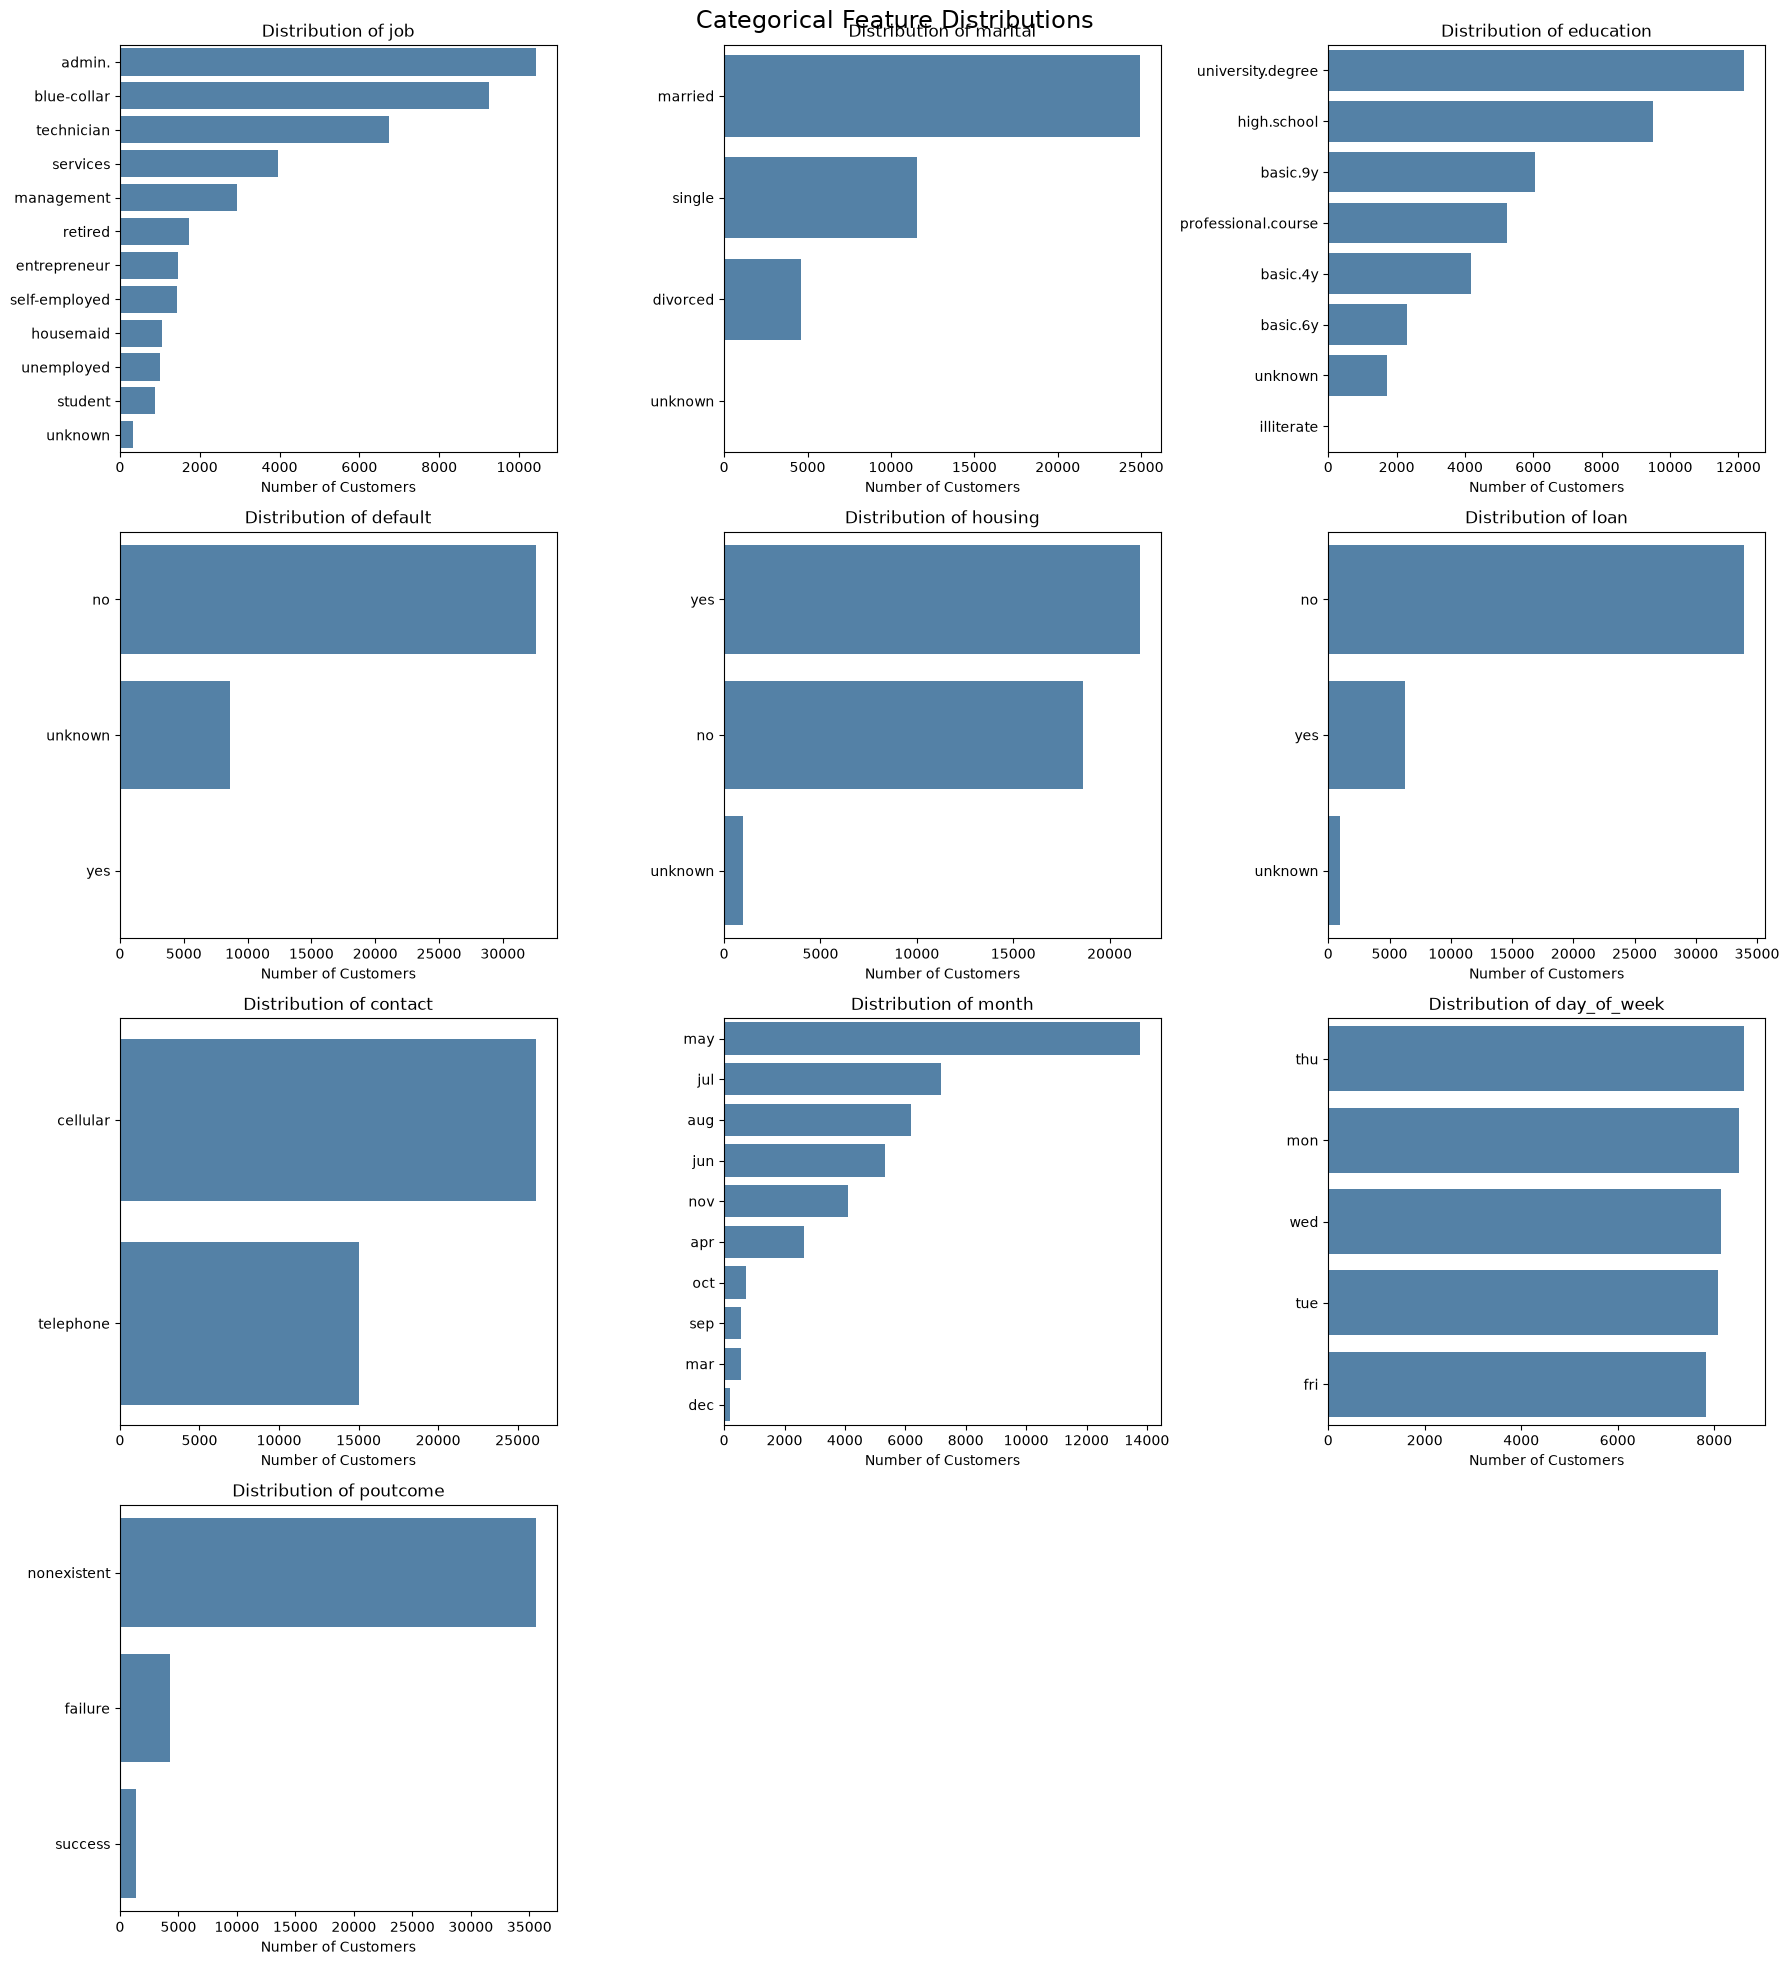

In [11]:
categorical_cols = df.select_dtypes(include=['str']).columns.drop('y')

n_cols = 3
n_rows = int(np.ceil(len(categorical_cols) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        ax=axes[i],
        color='steelblue'
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Number of Customers')
    axes[i].set_ylabel('')

# Hide unused plot spaces
for j in range(len(categorical_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Categorical Feature Distributions', fontsize=17)
plt.tight_layout()
plt.savefig('categorical_feature_distributions.png', dpi=300)
plt.show()

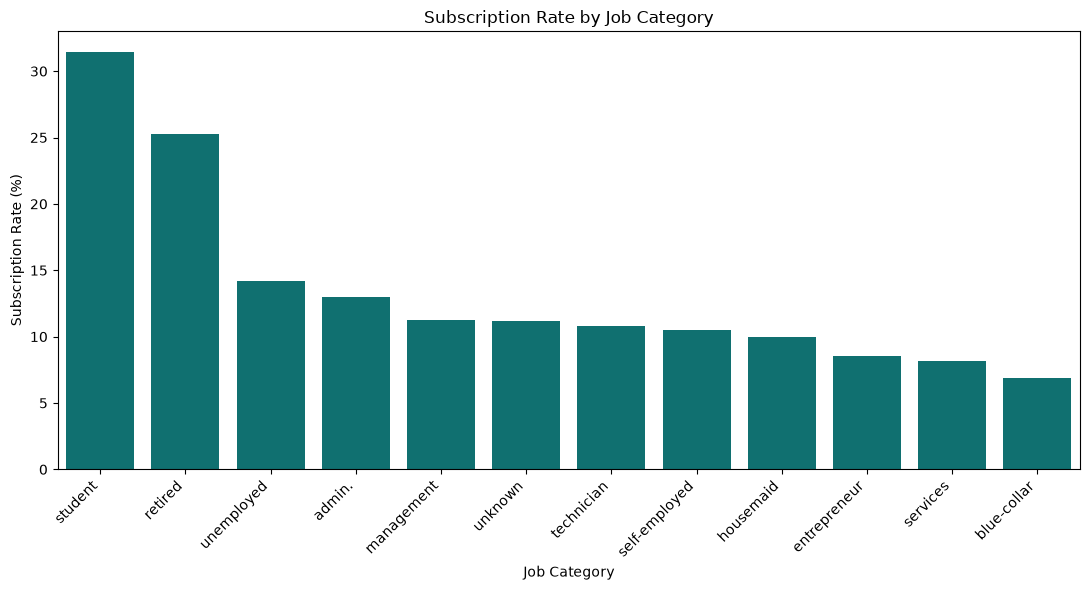

y,no,yes
job,,
student,68.57,31.43
retired,74.74,25.26
unemployed,85.80,14.20
admin.,87.03,12.97
management,88.78,11.22
unknown,88.79,11.21
technician,89.17,10.83
self-employed,89.51,10.49
housemaid,90.00,10.00


In [12]:
job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_subscription = job_subscription.sort_values(
    by='yes',
    ascending=False
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=job_subscription.index,
    y=job_subscription['yes'],
    color='teal'
)

plt.title('Subscription Rate by Job Category')
plt.xlabel('Job Category')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig('subscription_rate_by_job.png', dpi=300)
plt.show()

display(job_subscription.round(2))

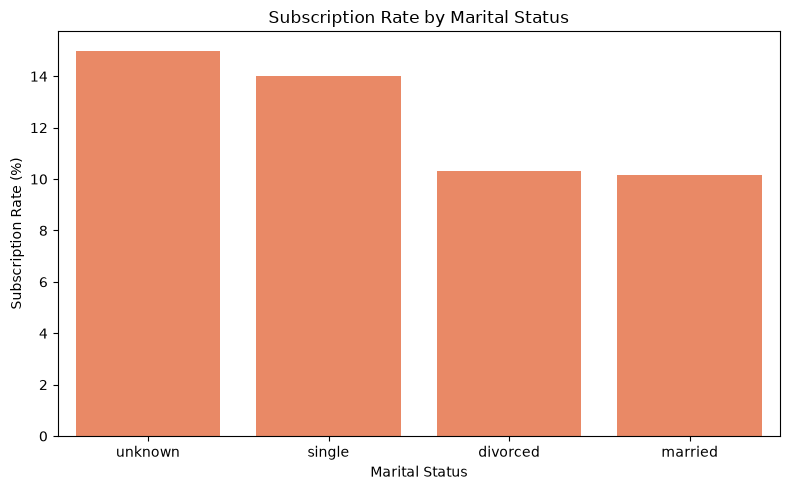

y,no,yes
marital,,
unknown,85.00,15.00
single,85.99,14.01
divorced,89.68,10.32
married,89.84,10.16


In [13]:
marital_subscription = pd.crosstab(
    df['marital'],
    df['y'],
    normalize='index'
) * 100

marital_subscription = marital_subscription.sort_values(
    by='yes',
    ascending=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_subscription.index,
    y=marital_subscription['yes'],
    color='coral'
)

plt.title('Subscription Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Subscription Rate (%)')
plt.tight_layout()

plt.savefig('subscription_rate_by_marital_status.png', dpi=300)
plt.show()

display(marital_subscription.round(2))

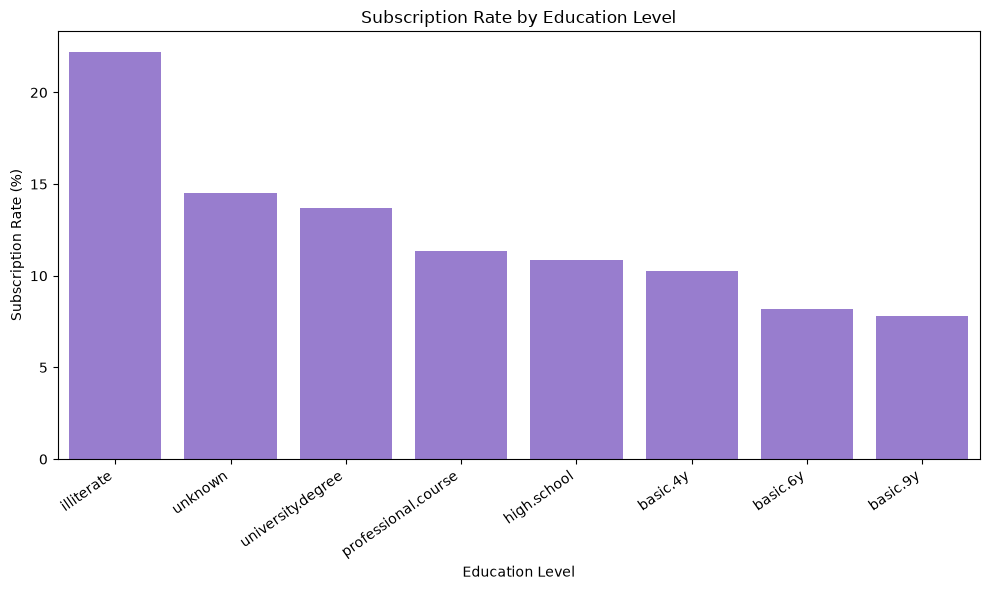

y,no,yes
education,,
illiterate,77.78,22.22
unknown,85.49,14.51
university.degree,86.28,13.72
professional.course,88.65,11.35
high.school,89.16,10.84
basic.4y,89.75,10.25
basic.6y,91.79,8.21
basic.9y,92.18,7.82


In [14]:
education_subscription = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

education_subscription = education_subscription.sort_values(
    by='yes',
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=education_subscription.index,
    y=education_subscription['yes'],
    color='mediumpurple'
)

plt.title('Subscription Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()

plt.savefig('subscription_rate_by_education.png', dpi=300)
plt.show()

display(education_subscription.round(2))

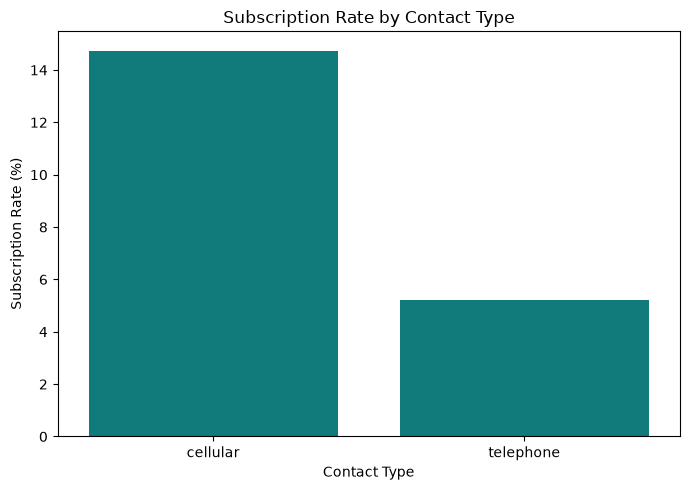

y,no,yes
contact,,
cellular,85.26,14.74
telephone,94.77,5.23


In [15]:
contact_subscription = pd.crosstab(
    df['contact'],
    df['y'],
    normalize='index'
) * 100

contact_subscription = contact_subscription.sort_values(
    by='yes',
    ascending=False
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=contact_subscription.index,
    y=contact_subscription['yes'],
    color='darkcyan'
)

plt.title('Subscription Rate by Contact Type')
plt.xlabel('Contact Type')
plt.ylabel('Subscription Rate (%)')
plt.tight_layout()

plt.savefig('subscription_rate_by_contact.png', dpi=300)
plt.show()

display(contact_subscription.round(2))

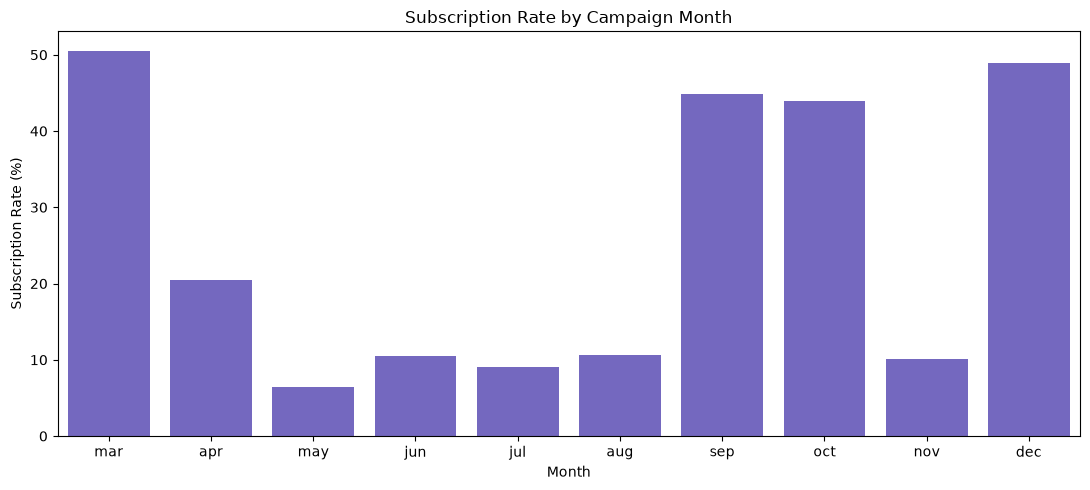

y,no,yes
month,,
mar,49.45,50.55
apr,79.51,20.49
may,93.56,6.44
jun,89.49,10.51
jul,90.96,9.04
aug,89.39,10.61
sep,55.09,44.91
oct,56.07,43.93
nov,89.85,10.15


In [16]:
month_order = [
    'mar', 'apr', 'may', 'jun', 'jul', 'aug',
    'sep', 'oct', 'nov', 'dec'
]

month_subscription = pd.crosstab(
    df['month'],
    df['y'],
    normalize='index'
) * 100

month_subscription = month_subscription.reindex(month_order)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=month_subscription.index,
    y=month_subscription['yes'],
    color='slateblue'
)

plt.title('Subscription Rate by Campaign Month')
plt.xlabel('Month')
plt.ylabel('Subscription Rate (%)')
plt.tight_layout()

plt.savefig('subscription_rate_by_month.png', dpi=300)
plt.show()

display(month_subscription.round(2))

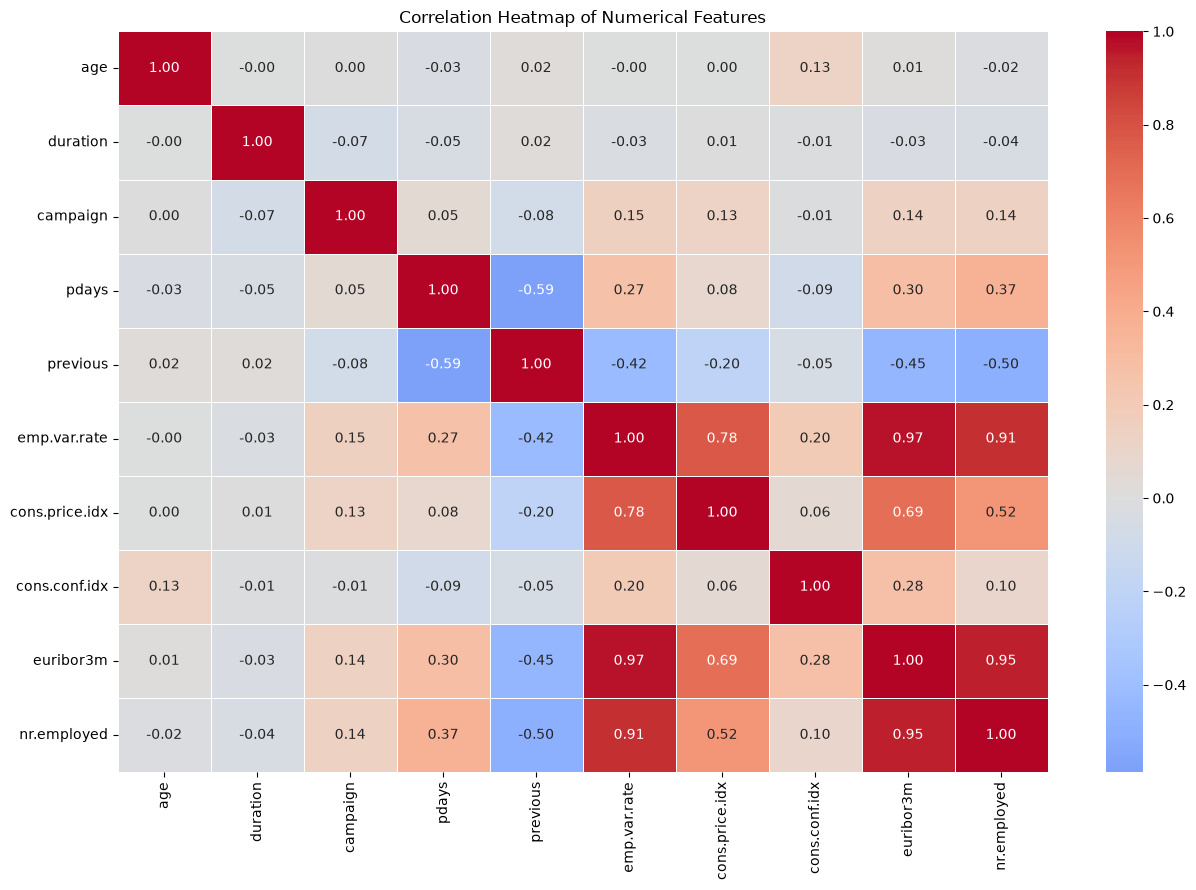

In [17]:
plt.figure(figsize=(13, 9))

correlation_matrix = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()

plt.savefig('numerical_correlation_heatmap.png', dpi=300)
plt.show()

In [18]:
# Convert target variable into binary values
df['y'] = df['y'].map({
    'no': 0,
    'yes': 1
})

# Remove duration to prevent data leakage
X = df.drop(columns=['y', 'duration'])
y = df['y']

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

Feature dataset shape: (41176, 19)
Target dataset shape: (41176,)

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64

Target percentages:
y
0    88.73
1    11.27
Name: proportion, dtype: float64


In [19]:
from sklearn.model_selection import train_test_split

# Identify feature types
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(include=['str']).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nNumber of Numerical Features:", len(numeric_features))

print("\nCategorical Features:", categorical_features)
print("\nNumber of Categorical Features:", len(categorical_features))

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Numerical Features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of Numerical Features: 9

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of Categorical Features: 10

Training Features: (32940, 19)
Testing Features: (8236, 19)

Training Target Distribution:
y
0    0.887
1    0.113
Name: proportion, dtype: float64

Testing Target Distribution:
y
0    0.887
1    0.113
Name: proportion, dtype: float64


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [21]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [22]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    'Logistic Regression': logistic_model,
    'Random Forest': random_forest_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index('Model')

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8303,0.3591,0.6455,0.4615,0.8002
Random Forest,0.8738,0.4422,0.4580,0.4500,0.7851


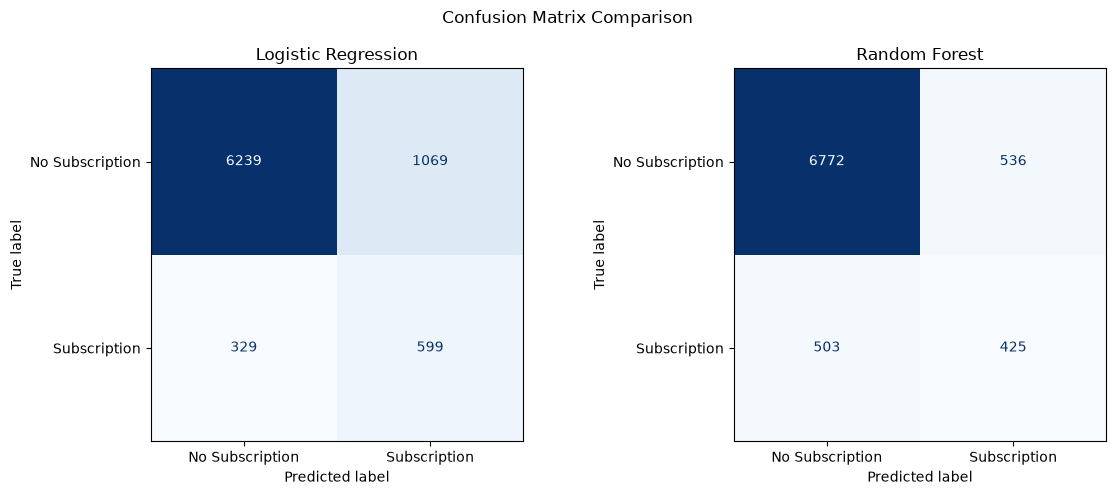

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No Subscription', 'Subscription']
    )

    display_cm.plot(
        ax=ax,
        cmap='Blues',
        values_format='d',
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.savefig('model_confusion_matrices.png', dpi=300)
plt.show()

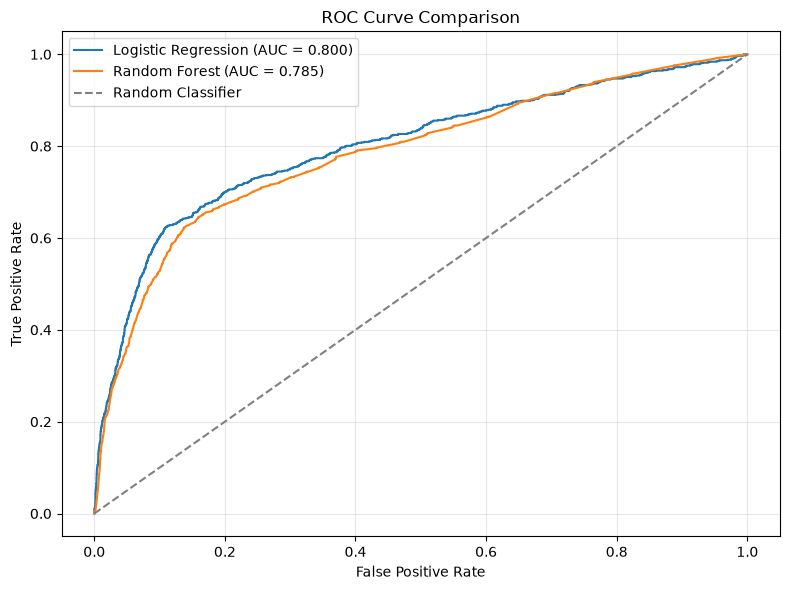

In [25]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {roc_auc:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('roc_curve_comparison.png', dpi=300)
plt.show()

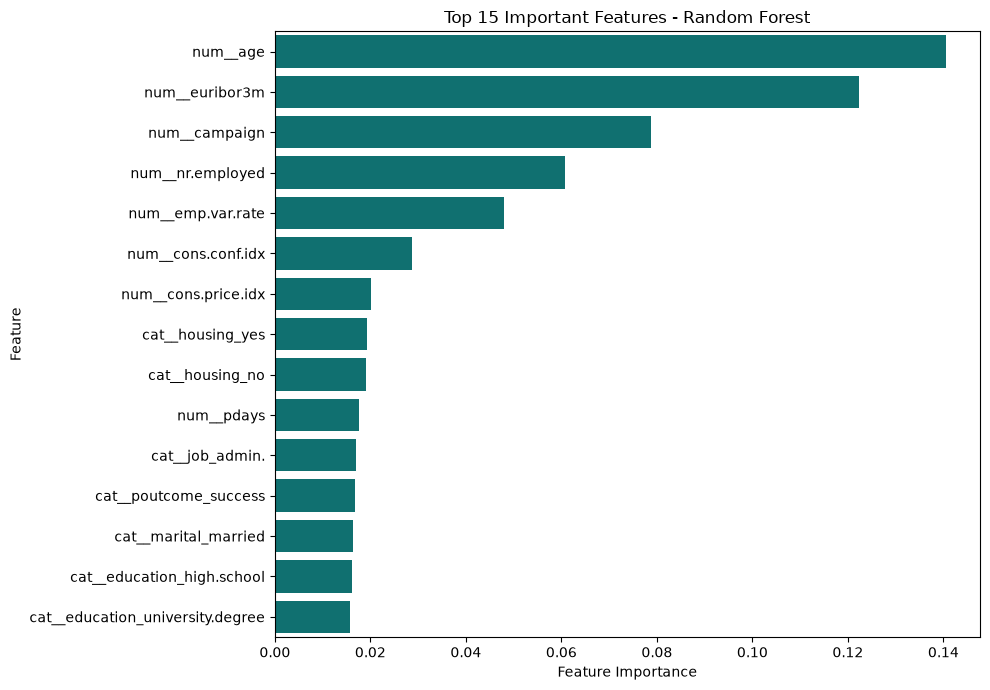

,Feature,Importance
0,num__age,0.140632
7,num__euribor3m,0.122340
1,num__campaign,0.078749
8,num__nr.employed,0.060802
4,num__emp.var.rate,0.047892
6,num__cons.conf.idx,0.028683
5,num__cons.price.idx,0.020099
38,cat__housing_yes,0.019246
36,cat__housing_no,0.019005
2,num__pdays,0.017645


In [26]:
# Extract trained Random Forest classifier
rf_classifier = random_forest_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = random_forest_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# Create feature importance dataframe
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature',
    color='teal'
)

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()

plt.savefig('random_forest_feature_importance.png', dpi=300)
plt.show()

display(top_features)

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select features for customer segmentation
cluster_features = [
    'age',
    'campaign',
    'previous',
    'pdays',
    'job',
    'marital',
    'education',
    'housing',
    'loan'
]

X_cluster = df[cluster_features].copy()

print("Clustering dataset shape:", X_cluster.shape)
print("\nSelected clustering features:")
print(cluster_features)

Clustering dataset shape: (41176, 9)

Selected clustering features:
['age', 'campaign', 'previous', 'pdays', 'job', 'marital', 'education', 'housing', 'loan']


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

cluster_numeric = X_cluster.select_dtypes(
    include=np.number
).columns.tolist()

cluster_categorical = X_cluster.select_dtypes(
    include=['str']
).columns.tolist()

cluster_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), cluster_numeric),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cluster_categorical)
    ]
)

X_cluster_scaled = cluster_preprocessor.fit_transform(X_cluster)

print("Clustering preprocessing completed!")
print("Transformed dataset shape:", X_cluster_scaled.shape)

Clustering preprocessing completed!
Transformed dataset shape: (41176, 34)


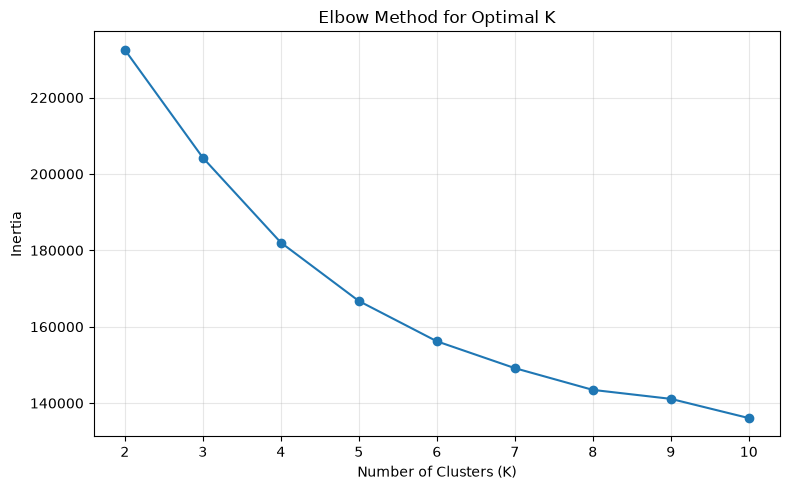

In [29]:
inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia_values,
    marker='o',
    linestyle='-'
)

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('kmeans_elbow_method.png', dpi=300)
plt.show()

K = 2, Silhouette Score = 0.5406
K = 3, Silhouette Score = 0.1473
K = 4, Silhouette Score = 0.1562
K = 5, Silhouette Score = 0.1645
K = 6, Silhouette Score = 0.1360
K = 7, Silhouette Score = 0.1283
K = 8, Silhouette Score = 0.1278
K = 9, Silhouette Score = 0.1181
K = 10, Silhouette Score = 0.1200


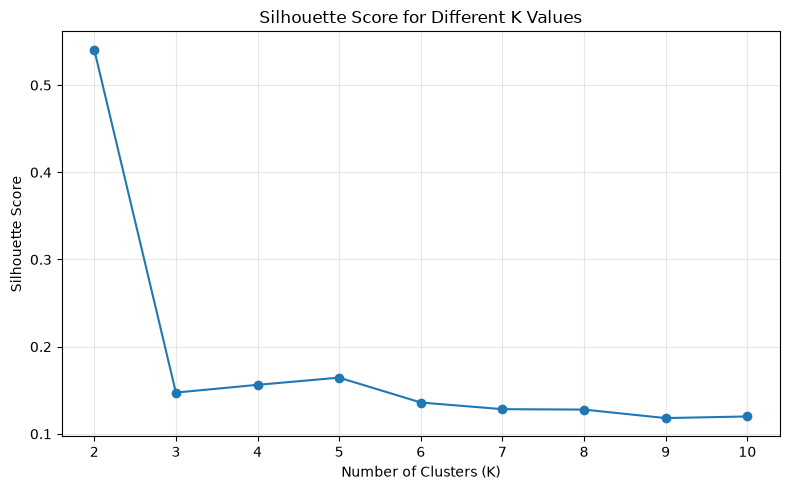

In [30]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_scaled)

    score = silhouette_score(
        X_cluster_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('kmeans_silhouette_analysis.png', dpi=300)
plt.show()

In [31]:
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df['Cluster'] = final_kmeans.fit_predict(X_cluster_scaled)

print("K-Means clustering completed!")

print("\nCustomer distribution across clusters:")
print(df['Cluster'].value_counts().sort_index())

K-Means clustering completed!

Customer distribution across clusters:
Cluster
0    39596
1     1580
Name: count, dtype: int64


In [32]:
cluster_profile = df.groupby('Cluster').agg(
    Customer_Count=('age', 'count'),
    Average_Age=('age', 'mean'),
    Average_Campaign_Contacts=('campaign', 'mean'),
    Average_Previous_Contacts=('previous', 'mean'),
    Average_Pdays=('pdays', 'mean'),
    Subscription_Rate=('y', 'mean')
)

cluster_profile['Subscription_Rate'] *= 100

print("Customer Segment Profiles:")
display(cluster_profile.round(2))

Customer Segment Profiles:


,Customer_Count,Average_Age,Average_Campaign_Contacts,Average_Previous_Contacts,Average_Pdays,Subscription_Rate
Cluster,,,,,,
0,39596,39.95,2.60,0.11,999.00,9.24
1,1580,41.76,1.84,1.73,46.87,61.96


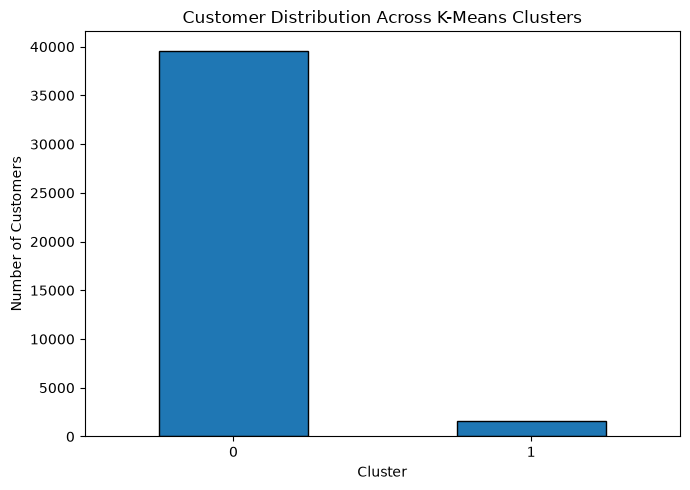

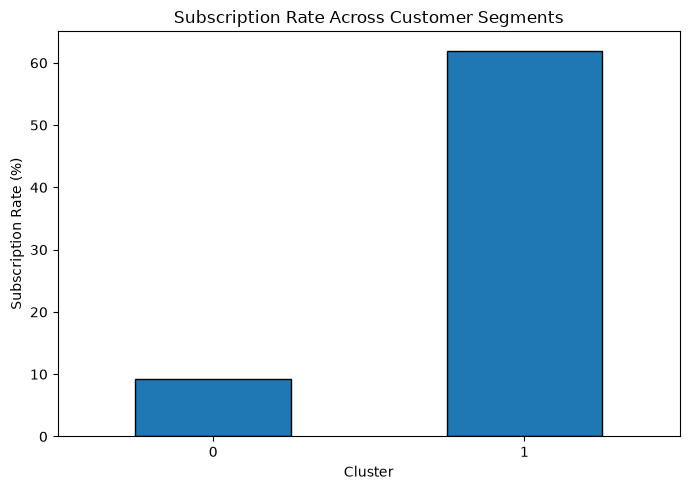

In [33]:
plt.figure(figsize=(7, 5))

df['Cluster'].value_counts().sort_index().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Customer Distribution Across K-Means Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('customer_cluster_distribution.png', dpi=300)
plt.show()


plt.figure(figsize=(7, 5))

cluster_profile['Subscription_Rate'].plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Subscription Rate Across Customer Segments')
plt.xlabel('Cluster')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('subscription_rate_by_cluster.png', dpi=300)
plt.show()

In [34]:
df.to_csv('bank_marketing_cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)
print("Files saved in:", os.getcwd())

Cleaned dataset saved successfully!
Final dataset shape: (41176, 22)
Files saved in: C:\Users\LaptopUser\Documents\Python_Integrative_Capstone_Week6


In [35]:
import os

image_files = [
    file for file in os.listdir()
    if file.endswith('.png')
]

print("Total visualisations:", len(image_files))

for file in sorted(image_files):
    print(file)

Total visualisations: 16
categorical_feature_distributions.png
customer_cluster_distribution.png
kmeans_elbow_method.png
kmeans_silhouette_analysis.png
model_confusion_matrices.png
numerical_correlation_heatmap.png
numerical_feature_distributions.png
random_forest_feature_importance.png
roc_curve_comparison.png
subscription_rate_by_cluster.png
subscription_rate_by_contact.png
subscription_rate_by_education.png
subscription_rate_by_job.png
subscription_rate_by_marital_status.png
subscription_rate_by_month.png
target_distribution.png


In [37]:
import sys
!{sys.executable} -m pip install python-docx


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Users\LaptopUser\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [38]:
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
import os

doc = Document()

# Page setup
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

# Default font
styles = doc.styles
styles['Normal'].font.name = 'Calibri'
styles['Normal'].font.size = Pt(10.5)

# Title page
title = doc.add_heading(
    'BANK MARKETING CAMPAIGN ANALYSIS AND CUSTOMER SUBSCRIPTION PREDICTION',
    0
)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
run = p.add_run('\nINTEGRATIVE CAPSTONE PROJECT\n')
run.bold = True
run.font.size = Pt(16)

p.add_run('\nData Science with Python Internship\n\n')
p.add_run('Project Report\n\n')
p.add_run('Submitted as part of the Virtual Data Science with Python Internship')

doc.add_page_break()

# Helper functions
def add_heading(text, level=1):
    doc.add_heading(text, level=level)

def add_para(text):
    doc.add_paragraph(text)

def add_image(filename, caption, width=5.8):
    if os.path.exists(filename):
        p = doc.add_paragraph()
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER
        p.add_run().add_picture(filename, width=Inches(width))
        cap = doc.add_paragraph(caption)
        cap.alignment = WD_ALIGN_PARAGRAPH.CENTER
        cap.runs[0].italic = True
    else:
        add_para(f"[Figure unavailable: {filename}]")

def add_table(headers, rows):
    table = doc.add_table(rows=1, cols=len(headers))
    table.style = 'Light Shading Accent 1'
    table.alignment = WD_TABLE_ALIGNMENT.CENTER

    for i, header in enumerate(headers):
        table.rows[0].cells[i].text = str(header)

    for row in rows:
        cells = table.add_row().cells
        for i, value in enumerate(row):
            cells[i].text = str(value)

    doc.add_paragraph()

# Abstract
add_heading('ABSTRACT')
add_para(
    "This project presents an end-to-end data science analysis of a bank "
    "marketing campaign dataset. The main objective is to understand customer "
    "characteristics and campaign outcomes, predict whether a customer will "
    "subscribe to a term deposit, and identify meaningful customer segments. "
    "The project includes data acquisition, cleaning, exploratory data "
    "analysis, preprocessing, supervised machine learning, unsupervised "
    "clustering, model evaluation and interpretation. Logistic Regression "
    "and Random Forest were used for subscription prediction, while K-Means "
    "was applied for customer segmentation. The findings demonstrate how "
    "data-driven analysis can support better campaign targeting and resource "
    "allocation."
)

# Introduction
add_heading('1. INTRODUCTION')
add_para(
    "Bank marketing campaigns involve contacting potential customers to "
    "promote financial products such as term deposits. Reaching every customer "
    "with equal effort may not be efficient. Data science techniques can help "
    "identify customer patterns, estimate subscription likelihood and support "
    "more focused marketing strategies."
)
add_para(
    "This project applies Python-based data science methods to analyse a "
    "Portuguese bank marketing dataset. Both supervised and unsupervised "
    "learning approaches are used to explore the data from different "
    "perspectives."
)

add_heading('1.1 Problem Statement', 2)
add_para(
    "To analyse bank marketing campaign data, identify patterns associated "
    "with customer subscription, develop machine learning models to predict "
    "term deposit subscriptions, and segment customers using clustering."
)

add_heading('1.2 Objectives', 2)
for item in [
    "Acquire and understand the bank marketing dataset.",
    "Inspect and clean duplicate and inconsistent records.",
    "Perform exploratory data analysis using statistical summaries and visualisations.",
    "Prepare numerical and categorical features for machine learning.",
    "Develop Logistic Regression and Random Forest classification models.",
    "Evaluate model performance using suitable classification metrics.",
    "Identify important predictive features.",
    "Apply K-Means clustering to identify customer segments.",
    "Derive insights and recommendations from the results."
]:
    doc.add_paragraph(item, style='List Bullet')

# Dataset
add_heading('2. DATASET DESCRIPTION')
add_para(
    "The Bank Marketing dataset was obtained from the UCI Machine Learning "
    "Repository. It contains information related to direct marketing "
    "campaigns conducted by a Portuguese banking institution."
)
add_para(
    "The bank-additional-full.csv file contains 41,188 records and 21 columns, "
    "including 20 input attributes and the target variable y. The target "
    "indicates whether the customer subscribed to a term deposit."
)
add_para(
    "The attributes include demographic information, contact details, "
    "campaign history and economic indicators. Examples include age, job, "
    "marital status, education, campaign, previous, pdays and euribor3m."
)

add_heading('3. DATA CLEANING AND PREPROCESSING')
add_para(
    "The dataset was loaded using Pandas. Initial inspection was performed "
    "using shape, info, descriptive statistics and missing-value checks."
)
add_para(
    "The original dataset contained 12 duplicate rows. These were removed, "
    "resulting in 41,176 records. No conventional null values were detected. "
    "However, several categorical attributes contained the value 'unknown'. "
    "These values were retained as a separate category rather than being "
    "removed, since they represent unavailable information."
)
add_para(
    "The target variable y was encoded as 0 for 'no' and 1 for 'yes'. "
    "The duration attribute was excluded from predictive modelling because "
    "it is only known after a call has taken place. Including it would create "
    "target leakage and would not reflect a genuine pre-call prediction task."
)
add_para(
    "Numerical features were standardised using StandardScaler, while "
    "categorical features were converted into numerical representations "
    "using OneHotEncoder. A ColumnTransformer and Pipeline were used to "
    "organise preprocessing and modelling."
)

# EDA
add_heading('4. EXPLORATORY DATA ANALYSIS')
add_para(
    "Exploratory data analysis was performed to understand the distribution "
    "of customer attributes, target imbalance and relationships between "
    "features and subscription outcomes."
)

add_heading('4.1 Target Distribution', 2)
add_para(
    "After duplicate removal, 36,537 customers did not subscribe and 4,639 "
    "customers subscribed. Approximately 88.73% of records belong to the "
    "non-subscription class and 11.27% to the subscription class. This "
    "indicates substantial class imbalance."
)
add_image('target_distribution.png', 'Figure 1: Distribution of the target variable.')

add_heading('4.2 Numerical Feature Distributions', 2)
add_para(
    "Histograms were used to inspect the distributions of numerical "
    "attributes such as age, campaign contacts, previous contacts and "
    "economic indicators."
)
add_image('numerical_feature_distributions.png', 'Figure 2: Numerical feature distributions.')

add_heading('4.3 Categorical Feature Distributions', 2)
add_para(
    "Categorical attributes including job, marital status, education, "
    "contact method, month and previous campaign outcome were examined "
    "using count plots."
)
add_image('categorical_feature_distributions.png', 'Figure 3: Categorical feature distributions.')

add_heading('4.4 Subscription Patterns', 2)
add_para(
    "Subscription rates varied across customer categories. Students and "
    "retired customers showed comparatively higher subscription rates "
    "among job categories. Cellular contact had a higher subscription rate "
    "than telephone contact. March, December, September and October showed "
    "higher observed subscription rates than several other months. These "
    "patterns should be interpreted with consideration of differences in "
    "category sample sizes."
)
add_image('subscription_rate_by_job.png', 'Figure 4: Subscription rate by job.')
add_image('subscription_rate_by_marital_status.png', 'Figure 5: Subscription rate by marital status.')
add_image('subscription_rate_by_education.png', 'Figure 6: Subscription rate by education.')
add_image('subscription_rate_by_contact.png', 'Figure 7: Subscription rate by contact method.')
add_image('subscription_rate_by_month.png', 'Figure 8: Subscription rate by month.')

add_heading('4.5 Correlation Analysis', 2)
add_para(
    "A correlation heatmap was generated to inspect relationships among "
    "numerical features. Economic indicators such as employment variation, "
    "consumer confidence, consumer price index and Euribor rate provide "
    "additional context about the campaign period."
)
add_image('numerical_correlation_heatmap.png', 'Figure 9: Correlation heatmap of numerical features.')

# Supervised learning
add_heading('5. SUPERVISED MACHINE LEARNING')
add_para(
    "The objective of supervised learning was to predict whether a customer "
    "would subscribe to a term deposit. The dataset was divided into training "
    "and testing sets using an 80:20 split. Stratified sampling was used to "
    "preserve the class distribution in both sets."
)

add_heading('5.1 Models Developed', 2)
add_para(
    "Logistic Regression was selected as a baseline classification model. "
    "The model used class_weight='balanced' to account for class imbalance."
)
add_para(
    "Random Forest was used as a second model. It combines multiple decision "
    "trees and can capture non-linear patterns in the data. Class weighting "
    "was also applied."
)

add_heading('5.2 Model Evaluation', 2)
add_para(
    "The models were evaluated using accuracy, precision, recall, F1-score "
    "and ROC-AUC. Since the target classes are imbalanced, accuracy alone "
    "is insufficient to assess performance."
)

add_table(
    ['Metric', 'Logistic Regression', 'Random Forest'],
    [
        ['Accuracy', '0.8303', '0.8738'],
        ['Precision', '0.3591', '0.4422'],
        ['Recall', '0.6455', '0.4580'],
        ['F1-Score', '0.4615', '0.4500'],
        ['ROC-AUC', '0.8002', '0.7851']
    ]
)

add_para(
    "Random Forest achieved higher accuracy and precision. Logistic "
    "Regression achieved higher recall, F1-score and ROC-AUC. Logistic "
    "Regression identified a larger proportion of actual subscribers, "
    "making it potentially more useful when the priority is to avoid "
    "missing interested customers. Random Forest produced fewer false "
    "positive predictions relative to its predicted positive cases."
)

add_image('model_confusion_matrices.png', 'Figure 10: Confusion matrices of the classification models.')
add_image('roc_curve_comparison.png', 'Figure 11: ROC curve comparison.')

add_heading('5.3 Feature Importance', 2)
add_para(
    "Random Forest feature importance was used to identify attributes that "
    "contributed most to the model's predictions. Age had the highest "
    "importance, followed by Euribor three-month rate, campaign contacts, "
    "number of employees and employment variation rate. These values "
    "indicate predictive contribution and should not be interpreted as "
    "evidence of causation."
)
add_table(
    ['Feature', 'Importance'],
    [
        ['age', '0.140632'],
        ['euribor3m', '0.122340'],
        ['campaign', '0.078749'],
        ['nr.employed', '0.060802'],
        ['emp.var.rate', '0.047892'],
        ['cons.conf.idx', '0.028683'],
        ['cons.price.idx', '0.020099'],
        ['housing_yes', '0.019246'],
        ['housing_no', '0.019005'],
        ['pdays', '0.017645']
    ]
)
add_image('random_forest_feature_importance.png', 'Figure 12: Top features identified by Random Forest.')

# Unsupervised
add_heading('6. UNSUPERVISED LEARNING: K-MEANS CLUSTERING')
add_para(
    "K-Means clustering was applied to explore customer segments without "
    "using the subscription target during cluster formation. The selected "
    "features included age, campaign, previous, pdays, job, marital status, "
    "education, housing and loan."
)
add_para(
    "Numerical features were standardised and categorical features were "
    "one-hot encoded. The resulting feature matrix contained 34 encoded "
    "features. The elbow method and silhouette score were used to assess "
    "candidate cluster counts from 2 to 10."
)
add_image('kmeans_elbow_method.png', 'Figure 13: Elbow method for selecting K.')
add_image('kmeans_silhouette_analysis.png', 'Figure 14: Silhouette scores for different K values.')

add_para(
    "The highest silhouette score was obtained for K = 2, with a score of "
    "0.5406. The remaining tested values produced substantially lower scores, "
    "ranging from 0.1181 to 0.1645. Therefore, two clusters were selected "
    "for the final segmentation."
)

add_heading('6.1 Customer Segment Profiles', 2)
add_table(
    ['Measure', 'Cluster 0', 'Cluster 1'],
    [
        ['Customer count', '39,596', '1,580'],
        ['Average age', '39.95', '41.76'],
        ['Average campaign contacts', '2.60', '1.84'],
        ['Average previous contacts', '0.11', '1.73'],
        ['Average pdays', '999.00', '46.87'],
        ['Subscription rate', '9.24%', '61.96%']
    ]
)

add_para(
    "Cluster 0 represents the larger customer segment, containing 39,596 "
    "customers. It has a low average number of previous contacts and a "
    "subscription rate of 9.24%. The average pdays value of 999 indicates "
    "that many customers in this group had not previously been contacted "
    "during an earlier campaign."
)
add_para(
    "Cluster 1 contains 1,580 customers and has a substantially higher "
    "subscription rate of 61.96%. These customers have a higher average "
    "number of previous contacts and a much lower average pdays value, "
    "indicating more recent previous campaign contact."
)
add_para(
    "The clusters are highly unequal in size. Cluster 1 is a smaller segment "
    "but has a higher observed subscription rate. This makes it a potentially "
    "valuable group for further campaign analysis. The observed association "
    "does not establish that previous contact itself caused subscription."
)
add_image('customer_cluster_distribution.png', 'Figure 15: Customer distribution across clusters.')
add_image('subscription_rate_by_cluster.png', 'Figure 16: Subscription rate across clusters.')

# Insights
add_heading('7. KEY FINDINGS AND BUSINESS RECOMMENDATIONS')
for item in [
    "The dataset has a substantial class imbalance, with only about 11.27% of customers subscribing.",
    "Logistic Regression achieved better recall and ROC-AUC than Random Forest in the test evaluation.",
    "Age, Euribor rate and campaign contact count were among the most important Random Forest features.",
    "Cellular contact showed a higher observed subscription rate than telephone contact.",
    "Students and retired customers showed comparatively higher subscription rates among job categories.",
    "The smaller K-Means segment had a much higher observed subscription rate than the larger segment."
]:
    doc.add_paragraph(item, style='List Bullet')

add_para(
    "The bank could consider using model scores to prioritise customers for "
    "follow-up, while retaining human review and monitoring false positives. "
    "Campaign planning could examine contact channel and timing patterns. "
    "The smaller high-response segment could be studied further to understand "
    "its characteristics and whether similar customers can be identified "
    "reliably. Any targeting strategy should be validated on newer campaign "
    "data before deployment."
)

# Challenges
add_heading('8. CHALLENGES AND LIMITATIONS')
for item in [
    "The target variable was imbalanced, which made accuracy alone an inadequate evaluation measure.",
    "Categorical attributes contained 'unknown' values that required careful treatment.",
    "The dataset included a duration variable that could cause target leakage if used for pre-call prediction.",
    "One-hot encoding increased the dimensionality of the feature matrix.",
    "K-Means produced highly unequal cluster sizes, requiring careful interpretation of the smaller segment.",
    "The analysis is based on historical campaign data and may not generalise to different banks, regions or time periods.",
    "Feature importance and observed subscription rates describe associations and do not prove causation."
]:
    doc.add_paragraph(item, style='List Bullet')

# Reflection
add_heading('9. REFLECTION')
add_para(
    "This capstone project provided practical experience in carrying out "
    "a complete data science workflow, from acquiring and inspecting data "
    "to cleaning, visualisation, machine learning and interpretation. "
    "Working with both supervised and unsupervised methods helped demonstrate "
    "how different analytical approaches can answer complementary questions."
)
add_para(
    "An important learning outcome was recognising the effect of class "
    "imbalance and the need to compare multiple evaluation metrics. The "
    "exclusion of call duration also highlighted the importance of avoiding "
    "target leakage. The clustering exercise demonstrated that customer "
    "segments can differ substantially in size and observed behaviour."
)
add_para(
    "The project strengthened practical skills in Pandas, NumPy, Matplotlib, "
    "Seaborn and Scikit-learn, along with the use of preprocessing pipelines, "
    "classification models, model evaluation and K-Means clustering."
)

# Conclusion
add_heading('10. CONCLUSION')
add_para(
    "The project successfully implemented an end-to-end analysis of bank "
    "marketing campaign data. Exploratory analysis revealed differences in "
    "subscription rates across customer characteristics and contact patterns. "
    "Logistic Regression and Random Forest provided complementary predictive "
    "performance, with Logistic Regression achieving higher recall and "
    "ROC-AUC, while Random Forest achieved higher accuracy and precision. "
    "K-Means identified two customer segments with markedly different "
    "observed subscription rates. Overall, the results demonstrate the "
    "potential of data science techniques to support customer understanding "
    "and more focused marketing campaign planning."
)

# References
add_heading('11. REFERENCES')
add_para(
    "1. Moro, S., Rita, P., and Cortez, P. (2014). Bank Marketing. "
    "UCI Machine Learning Repository. "
    "https://doi.org/10.24432/C5K306"
)
add_para(
    "2. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. "
    "Journal of Machine Learning Research, 12, 2825–2830."
)
add_para(
    "3. McKinney, W. (2010). Data Structures for Statistical Computing in Python. "
    "Proceedings of the 9th Python in Science Conference."
)

# Save
report_name = 'Bank_Marketing_Capstone_Report.docx'
doc.save(report_name)

print("Report generated successfully!")
print("File:", os.path.abspath(report_name))
print("Size:", round(os.path.getsize(report_name) / 1024, 2), "KB")

Report generated successfully!
File: C:\Users\LaptopUser\Documents\Python_Integrative_Capstone_Week6\Bank_Marketing_Capstone_Report.docx
Size: 2052.95 KB


In [39]:
import os

required_files = [
    'Bank_Marketing_Capstone_Report.docx',
    'bank_marketing_cleaned.csv',
    'Bank_Marketing_Capstone.ipynb'
]

for file in required_files:
    if os.path.exists(file):
        size = os.path.getsize(file) / 1024
        print(f"✓ {file} | {size:.2f} KB")
    else:
        print(f"✗ Missing: {file}")

✓ Bank_Marketing_Capstone_Report.docx | 2052.95 KB
✓ bank_marketing_cleaned.csv | 4871.41 KB
✓ Bank_Marketing_Capstone.ipynb | 968.26 KB
